# PowerCo Churn: Exploratory Data Analysis 
BCG X data science simulation

Author - Emmanuel Kironji

**Goal:** understand each variable's distribution, how it relates to churn, and which data quirks need handling before feature engineering and modelling.


## Phase 0: Setup & load

In [89]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


client = pd.read_csv("C:/Users/KIRONJI/Desktop/BCG Data science simulation/data/raw/client_data.csv")
price = pd.read_csv("C:/Users/KIRONJI/Desktop/BCG Data science simulation/data/raw/price_data.csv")

# Parse dates
date_cols = ["date_activ", "date_end", "date_modif_prod", "date_renewal"]
for c in date_cols:
    client[c] = pd.to_datetime(client[c])
price["price_date"] = pd.to_datetime(price["price_date"])

- Formatting the dates to datetime as they can then be subtracted to analyze time trends in feature engineering section

## Phase 1: Structure & quality

In [92]:
print(client.shape, price.shape)
client.info()
display(client.head())

print("Nulls (client):", client.isna().sum().sum())
print("Nulls (price): ", price.isna().sum().sum())
print("Duplicate client ids:", client["id"].duplicated().sum())

num_cols = client.select_dtypes("number").columns.drop("churn").tolist()
cat_cols = ["channel_sales", "has_gas", "origin_up"]

display(client[num_cols].describe().T)
print("\nSkewness:")
print(client[num_cols].skew().sort_values(ascending=False).round(2))

neg = (client[num_cols] < 0).sum()
print("\nColumns with negatives:\n", neg[neg > 0])

(14606, 26) (193002, 8)
<class 'pandas.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              14606 non-null  str           
 1   channel_sales                   14606 non-null  str           
 2   cons_12m                        14606 non-null  int64         
 3   cons_gas_12m                    14606 non-null  int64         
 4   cons_last_month                 14606 non-null  int64         
 5   date_activ                      14606 non-null  datetime64[us]
 6   date_end                        14606 non-null  datetime64[us]
 7   date_modif_prod                 14606 non-null  datetime64[us]
 8   date_renewal                    14606 non-null  datetime64[us]
 9   forecast_cons_12m               14606 non-null  float64       
 10  forecast_cons_year              14606 non-null  int64    

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.00,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.00,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.00,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,0,0.0,19.83,0.146694,0.000000,44.311378,f,0.00,30.22,30.22,1,25.46,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,526,0.0,131.73,0.116900,0.100015,40.606701,f,52.32,44.91,44.91,1,47.98,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,19.800,0


Nulls (client): 0
Nulls (price):  0
Duplicate client ids: 0


,count,mean,std,min,25%,50%,75%,max
cons_12m,14606.0,159220.286252,573465.264198,0.0,5674.750000,14115.500000,40763.750000,6.207104e+06
cons_gas_12m,14606.0,28092.375325,162973.059057,0.0,0.000000,0.000000,0.000000,4.154590e+06
cons_last_month,14606.0,16090.269752,64364.196422,0.0,0.000000,792.500000,3383.000000,7.712030e+05
forecast_cons_12m,14606.0,1868.614880,2387.571531,0.0,494.995000,1112.875000,2401.790000,8.290283e+04
forecast_cons_year,14606.0,1399.762906,3247.786255,0.0,0.000000,314.000000,1745.750000,1.753750e+05
forecast_discount_energy,14606.0,0.966726,5.108289,0.0,0.000000,0.000000,0.000000,3.000000e+01
forecast_meter_rent_12m,14606.0,63.086871,66.165783,0.0,16.180000,18.795000,131.030000,5.993100e+02
forecast_price_energy_off_peak,14606.0,0.137283,0.024623,0.0,0.116340,0.143166,0.146348,2.739630e-01
forecast_price_energy_peak,14606.0,0.050491,0.049037,0.0,0.000000,0.084138,0.098837,1.959750e-01
forecast_price_pow_off_peak,14606.0,43.130056,4.485988,0.0,40.606701,44.311378,44.311378,5.926638e+01



Skewness:
net_margin                        36.57
forecast_cons_year                16.59
imp_cons                          13.20
cons_gas_12m                       9.60
nb_prod_act                        8.64
forecast_cons_12m                  7.16
cons_last_month                    6.39
cons_12m                           6.00
pow_max                            5.79
forecast_discount_energy           5.16
margin_net_pow_ele                 4.47
margin_gross_pow_ele               4.47
forecast_meter_rent_12m            1.51
num_years_antig                    1.45
forecast_price_energy_peak        -0.01
forecast_price_energy_off_peak    -0.12
forecast_price_pow_off_peak       -5.00
dtype: float64

Columns with negatives:
 Series([], dtype: int64)


**Feature AUC computation**

In [93]:
auc = pd.Series({c: roc_auc_score(client["churn"], client[c]) for c in num_cols})
display(auc.sub(0.5).abs().add(0.5).sort_values(ascending=False).round(3))

margin_net_pow_ele                0.600
margin_gross_pow_ele              0.600
num_years_antig                   0.581
forecast_meter_rent_12m           0.540
pow_max                           0.535
forecast_price_energy_peak        0.533
forecast_price_energy_off_peak    0.532
forecast_price_pow_off_peak       0.522
net_margin                        0.519
cons_gas_12m                      0.515
cons_last_month                   0.511
nb_prod_act                       0.511
forecast_cons_12m                 0.507
forecast_discount_energy          0.506
imp_cons                          0.505
forecast_cons_year                0.505
cons_12m                          0.502
dtype: float64



-  Data is clean structurally: no nulls, no duplicate ids, no negative values. The one hidden gap is `channel_sales`, where "MISSING" is a label , so it's missing data disguised as a category.

- Consumption, margin and forecast columns are heavily right-skewed. `net_margin` is the most extreme (skew ≈ 37), followed by `forecast_cons_year` (≈ 17), `imp_cons` (≈ 13) and `cons_gas_12m` (≈ 10). `forecast_price_pow_off_peak` is 
the only strongly left-skewed column (≈ -5).

- Net margin skew means a small number of clients contribute disproportionately to PowerCo's profit, so losing those few matters more than losing the typical client.

- The auc shows the predictive power for each of the features

- Skewness describes shape, not predictive power; Skewed columns like `cons_12m` have almost no churn signal on their own (single-variable AUC ≈ 0.50). Skewed columns  have almost no churn signal on their own



## Phase 2: Target balance

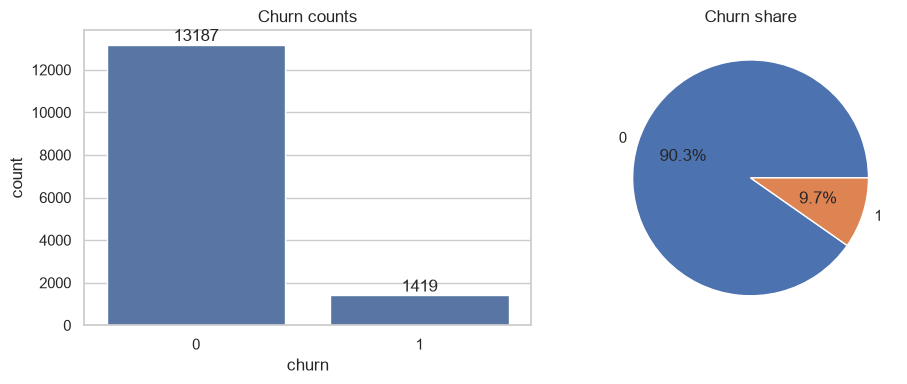

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=client, x="churn", ax=ax[0])
ax[0].set_title("Churn counts")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom")

client["churn"].value_counts().plot.pie(autopct="%.1f%%", ax=ax[1], ylabel="")
ax[1].set_title("Churn share")
plt.tight_layout(); plt.show()


- there are more loyal clients than churners thus a model will need to be undergo a class imbalance startegy ideally through class weighting and later evaluated through auc,recall and precision

## Phase 3: Numeric distributions (histograms + boxplots)

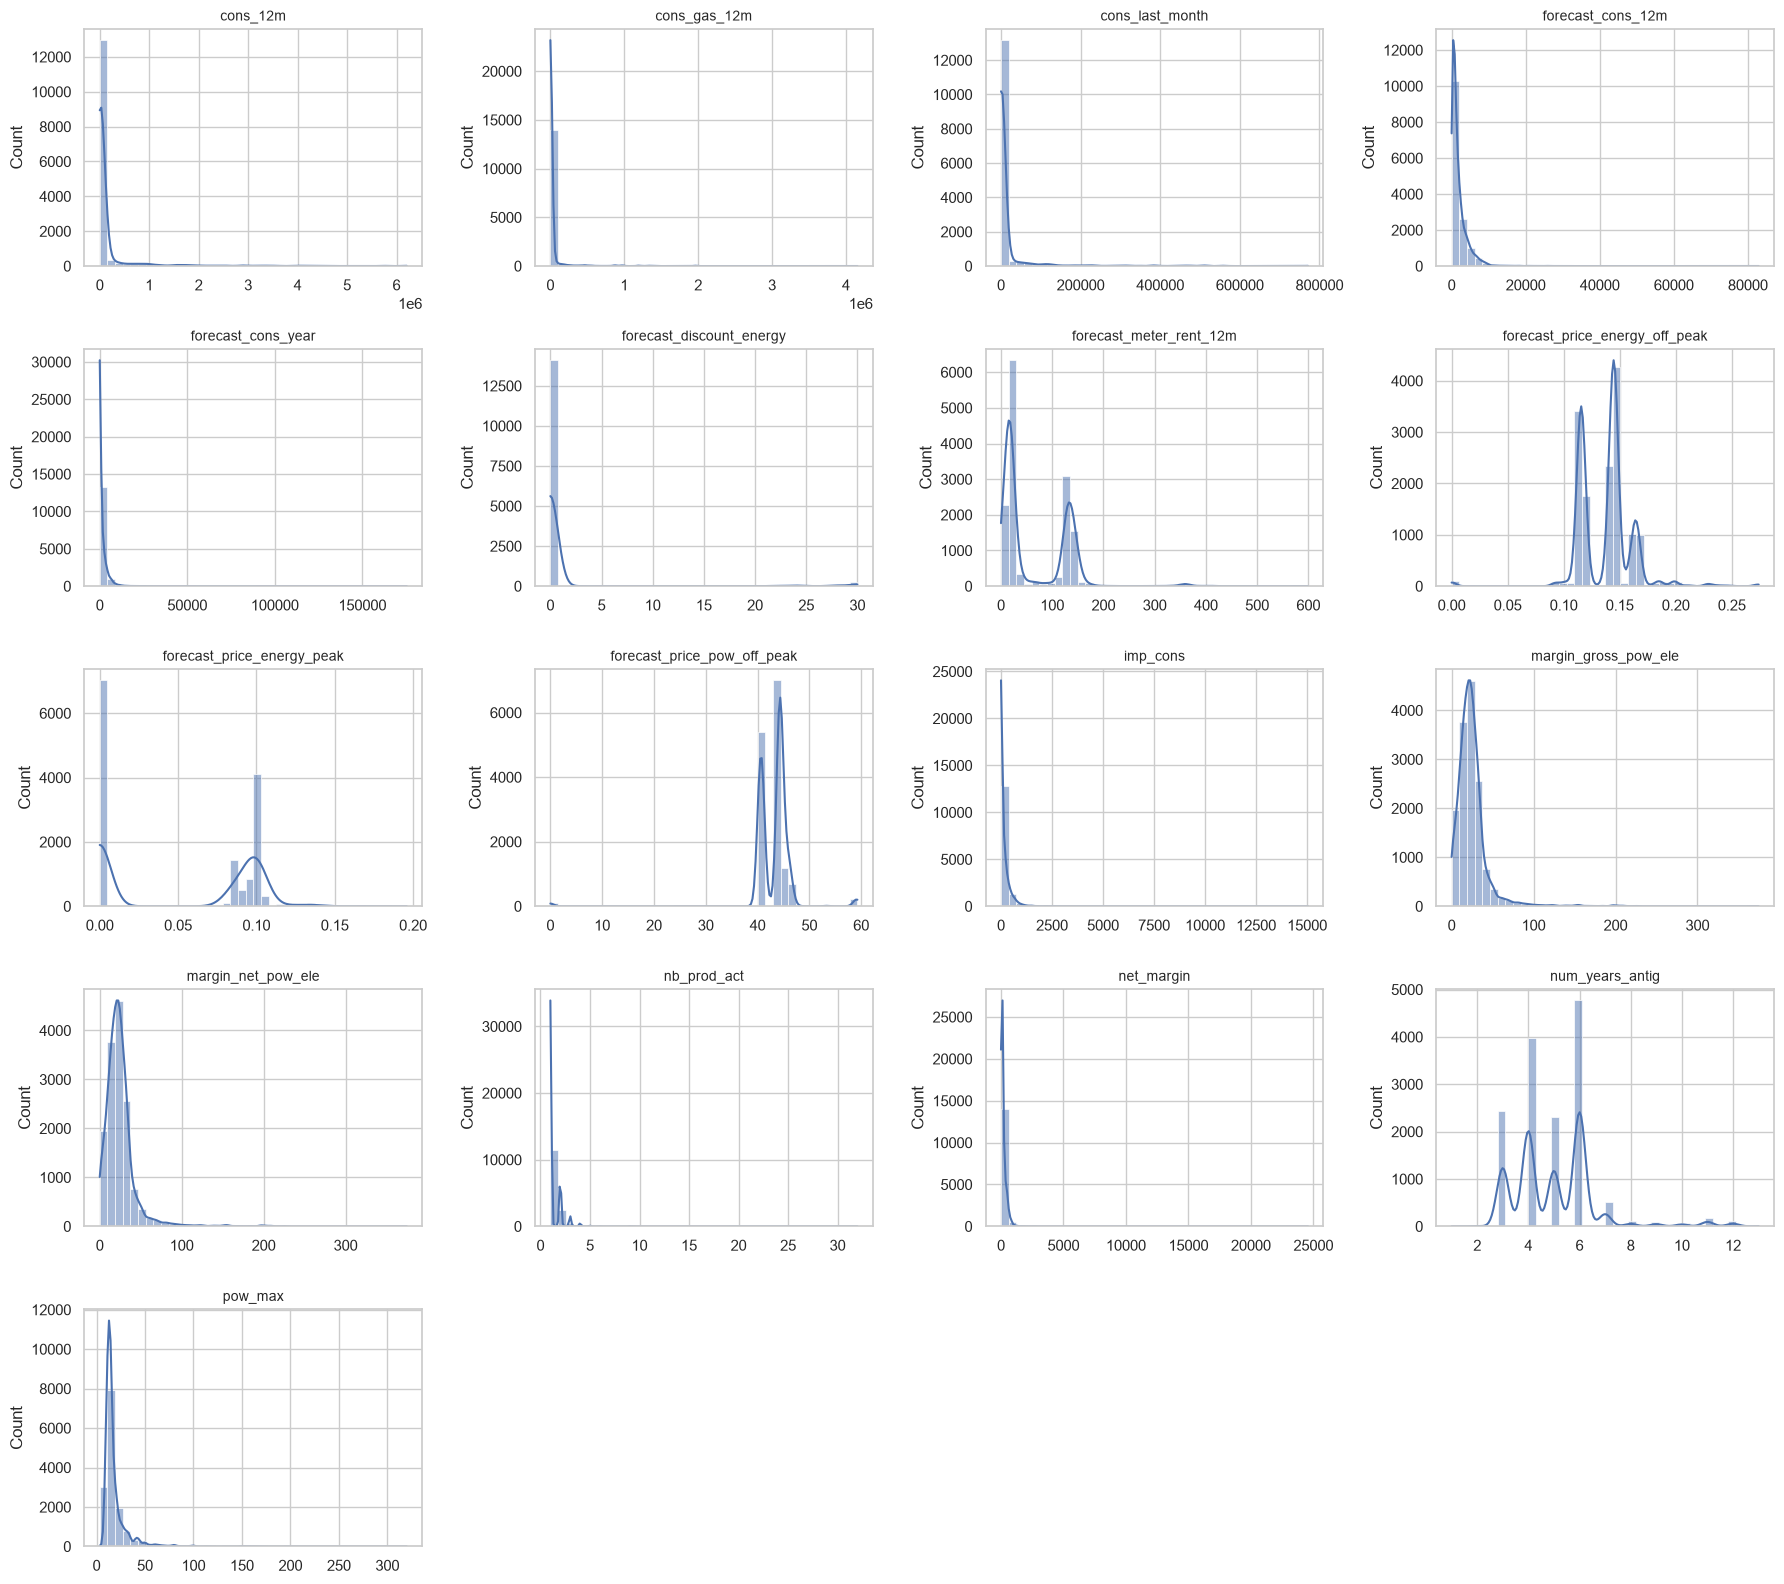

In [79]:
def dist_grid(df, cols, kind="hist", ncols=4, log=False):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes.ravel(), cols):
        x = df[c]
        if log:
            x = np.log1p(x.clip(lower=0))
        if kind == "hist":
            sns.histplot(x, bins=40, kde=True, ax=ax)
        else:
            sns.boxplot(x=x, ax=ax)
        ax.set_title(c + (" (log1p)" if log else ""), fontsize=10)
        ax.set_xlabel("")
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return fig, axes

hist_fig, hist_axes = dist_grid(client, num_cols, "hist")   # raw histograms

Skewed columns: ['cons_12m', 'cons_gas_12m', 'cons_last_month', 'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act', 'net_margin', 'num_years_antig', 'pow_max']


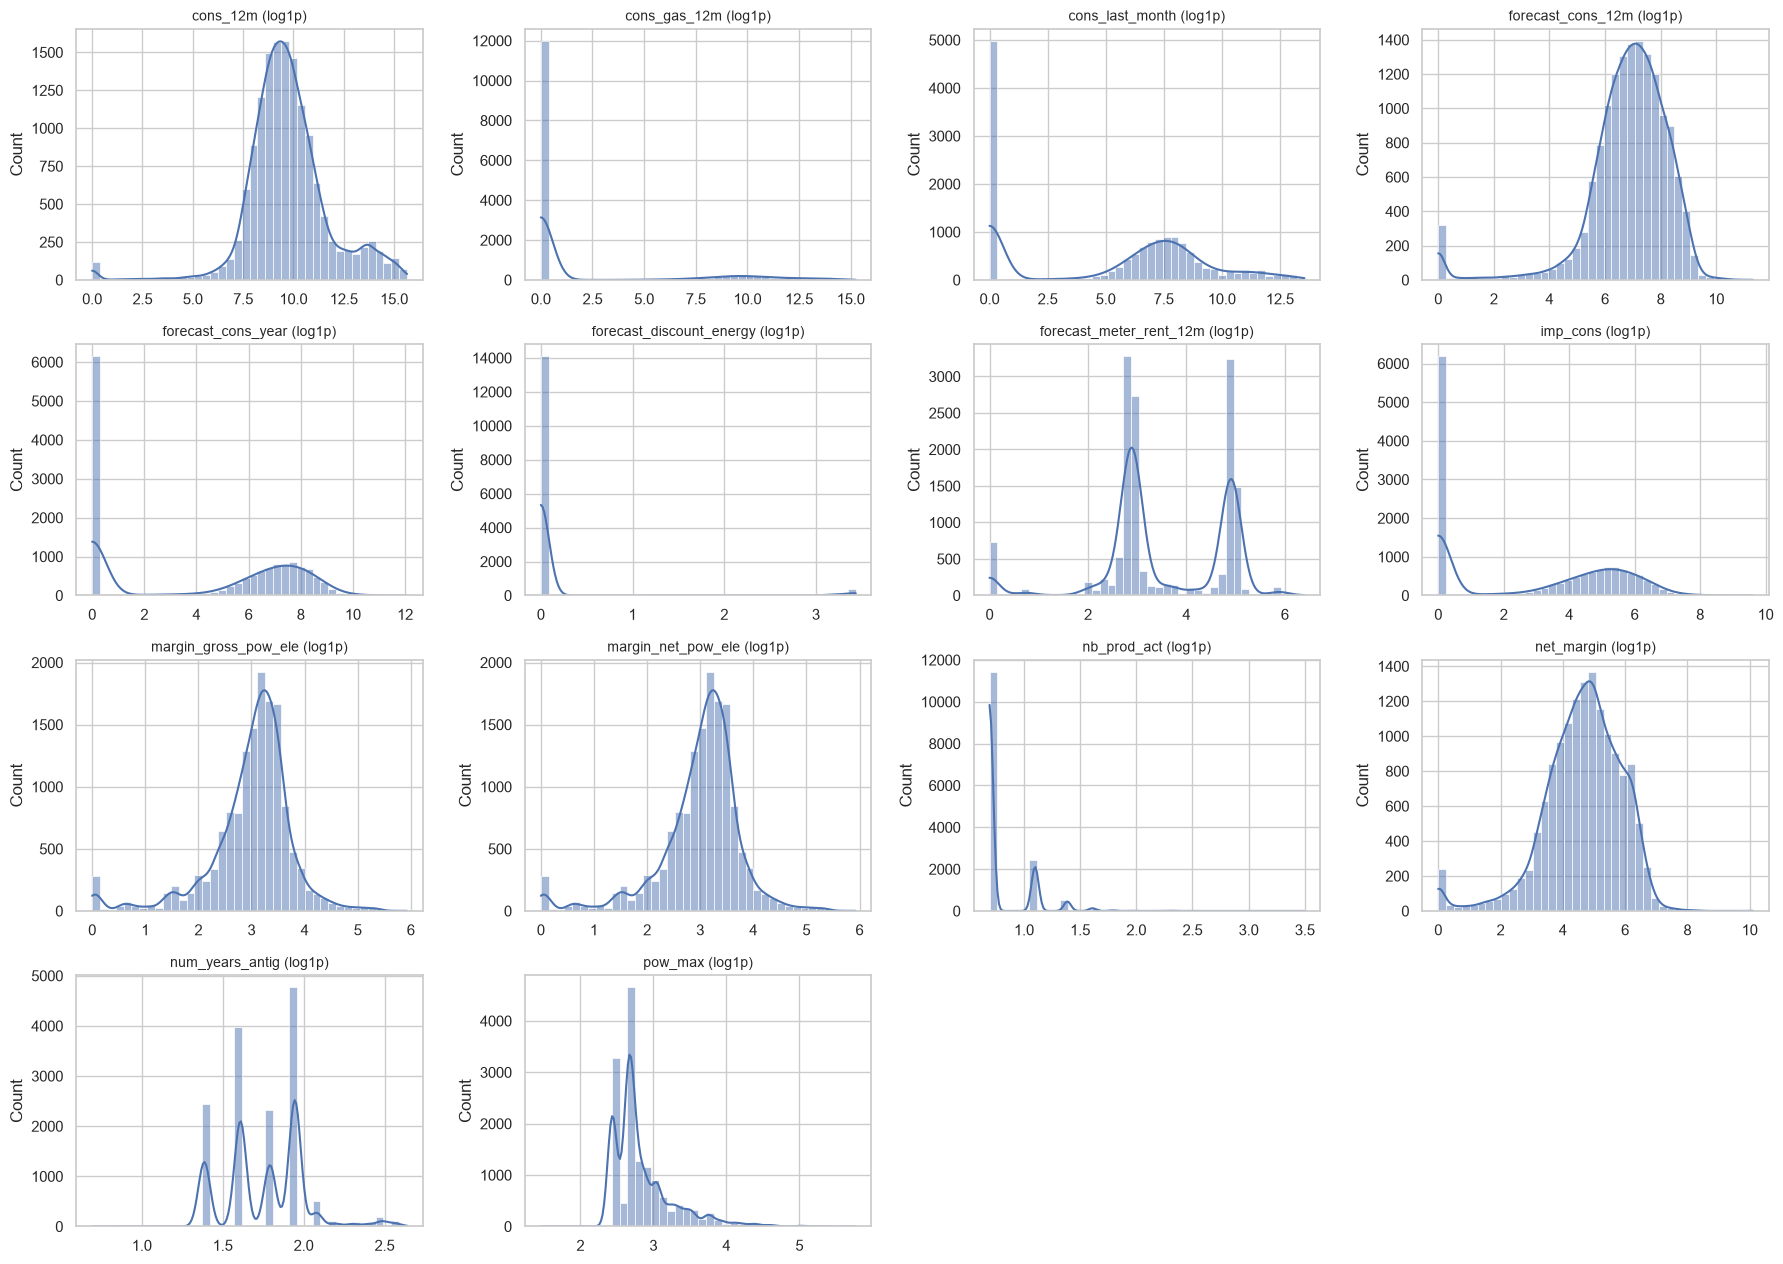

In [80]:
# Re-look at heavily skewed columns on a log scale
skewed = client[num_cols].skew()[lambda s: s > 1].index.tolist()
print("Skewed columns:", skewed)
log_hist_fig, log_hist_axes = dist_grid(client, skewed, "hist", log=True)

- Raw histograms show most consumption, margin and forecast columns piled up near zero with very long right tails (raw skew 4 to 37), so the raw scale hides their real shape.

- After log1p, the main consumption and margin columns look roughly bell-shaped: skew drops from 6.0 to -0.4 for `cons_12m`, 16.6 to -0.1 for `forecast_cons_year`, 13.2 to 0.0 for `imp_cons` and 36.6 to -1.0 for `net_margin`. Typical annual consumption is around e^9.6, about 14,000 units, with a few very large clients stretching the right tail.
- Log does not fix every column:

  - `cons_gas_12m`  and `forecast_discount_energy` are dominated by a spike at 0, so most clients simply have no gas contract or no discount.

  - The margin columns overshoot slightly into a left tail (skew ≈ -1.3 after log).

- Spikes at 0 also appear in `forecast_cons_year` and `imp_cons`  and `cons_last_month`. These are structural zeros 

- `forecast_meter_rent_12m` is bimodal, with peaks near log 3 (rent ≈ 19) and log 5 (rent ≈ 150). The two groups differ in size: the high-rent group has median `cons_12m` ≈ 27.5k vs 9.3k and higher `pow_max` (20 vs 13.2), so this looks like a smaller-contract vs larger-contract split in the client base.



## Phase 4: Active products countplot

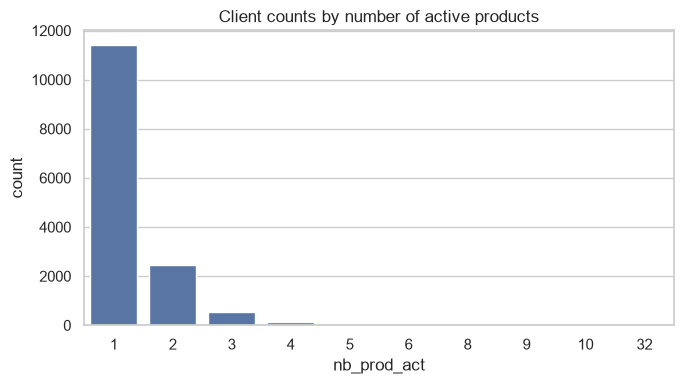

In [81]:
# nb_prod_act has only ~10 unique values, so treat it as categorical too
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=client, x="nb_prod_act", ax=ax)
ax.set_title("Client counts by number of active products")
plt.tight_layout(); plt.show()

In [90]:
display(client.groupby("nb_prod_act")["churn"].agg(["count", "mean"]).round(3))

,count,mean
nb_prod_act,,
1,11431,0.100
2,2445,0.085
3,523,0.099
4,150,0.100
5,31,0.097
6,8,0.000
8,4,0.000
9,11,0.000
10,2,0.000



- About 78% of clients (11,431 of 14,606) hold a single product and ~17% hold two. Counts above 5 products are tiny (a handful of clients each), so their churn rates aren't reliable.

- Churn rate is flat across product count: ~10.0% for 1 product, ~8.5% for 2 and ~9.9% for 3. Number of products does not separate churners from stayers.

- The chart shows PowerCo's base is mostly single-product.

- Keep `nb_prod_act` as a feature- not a main driver though

## Phase 5: Numeric variables vs churn

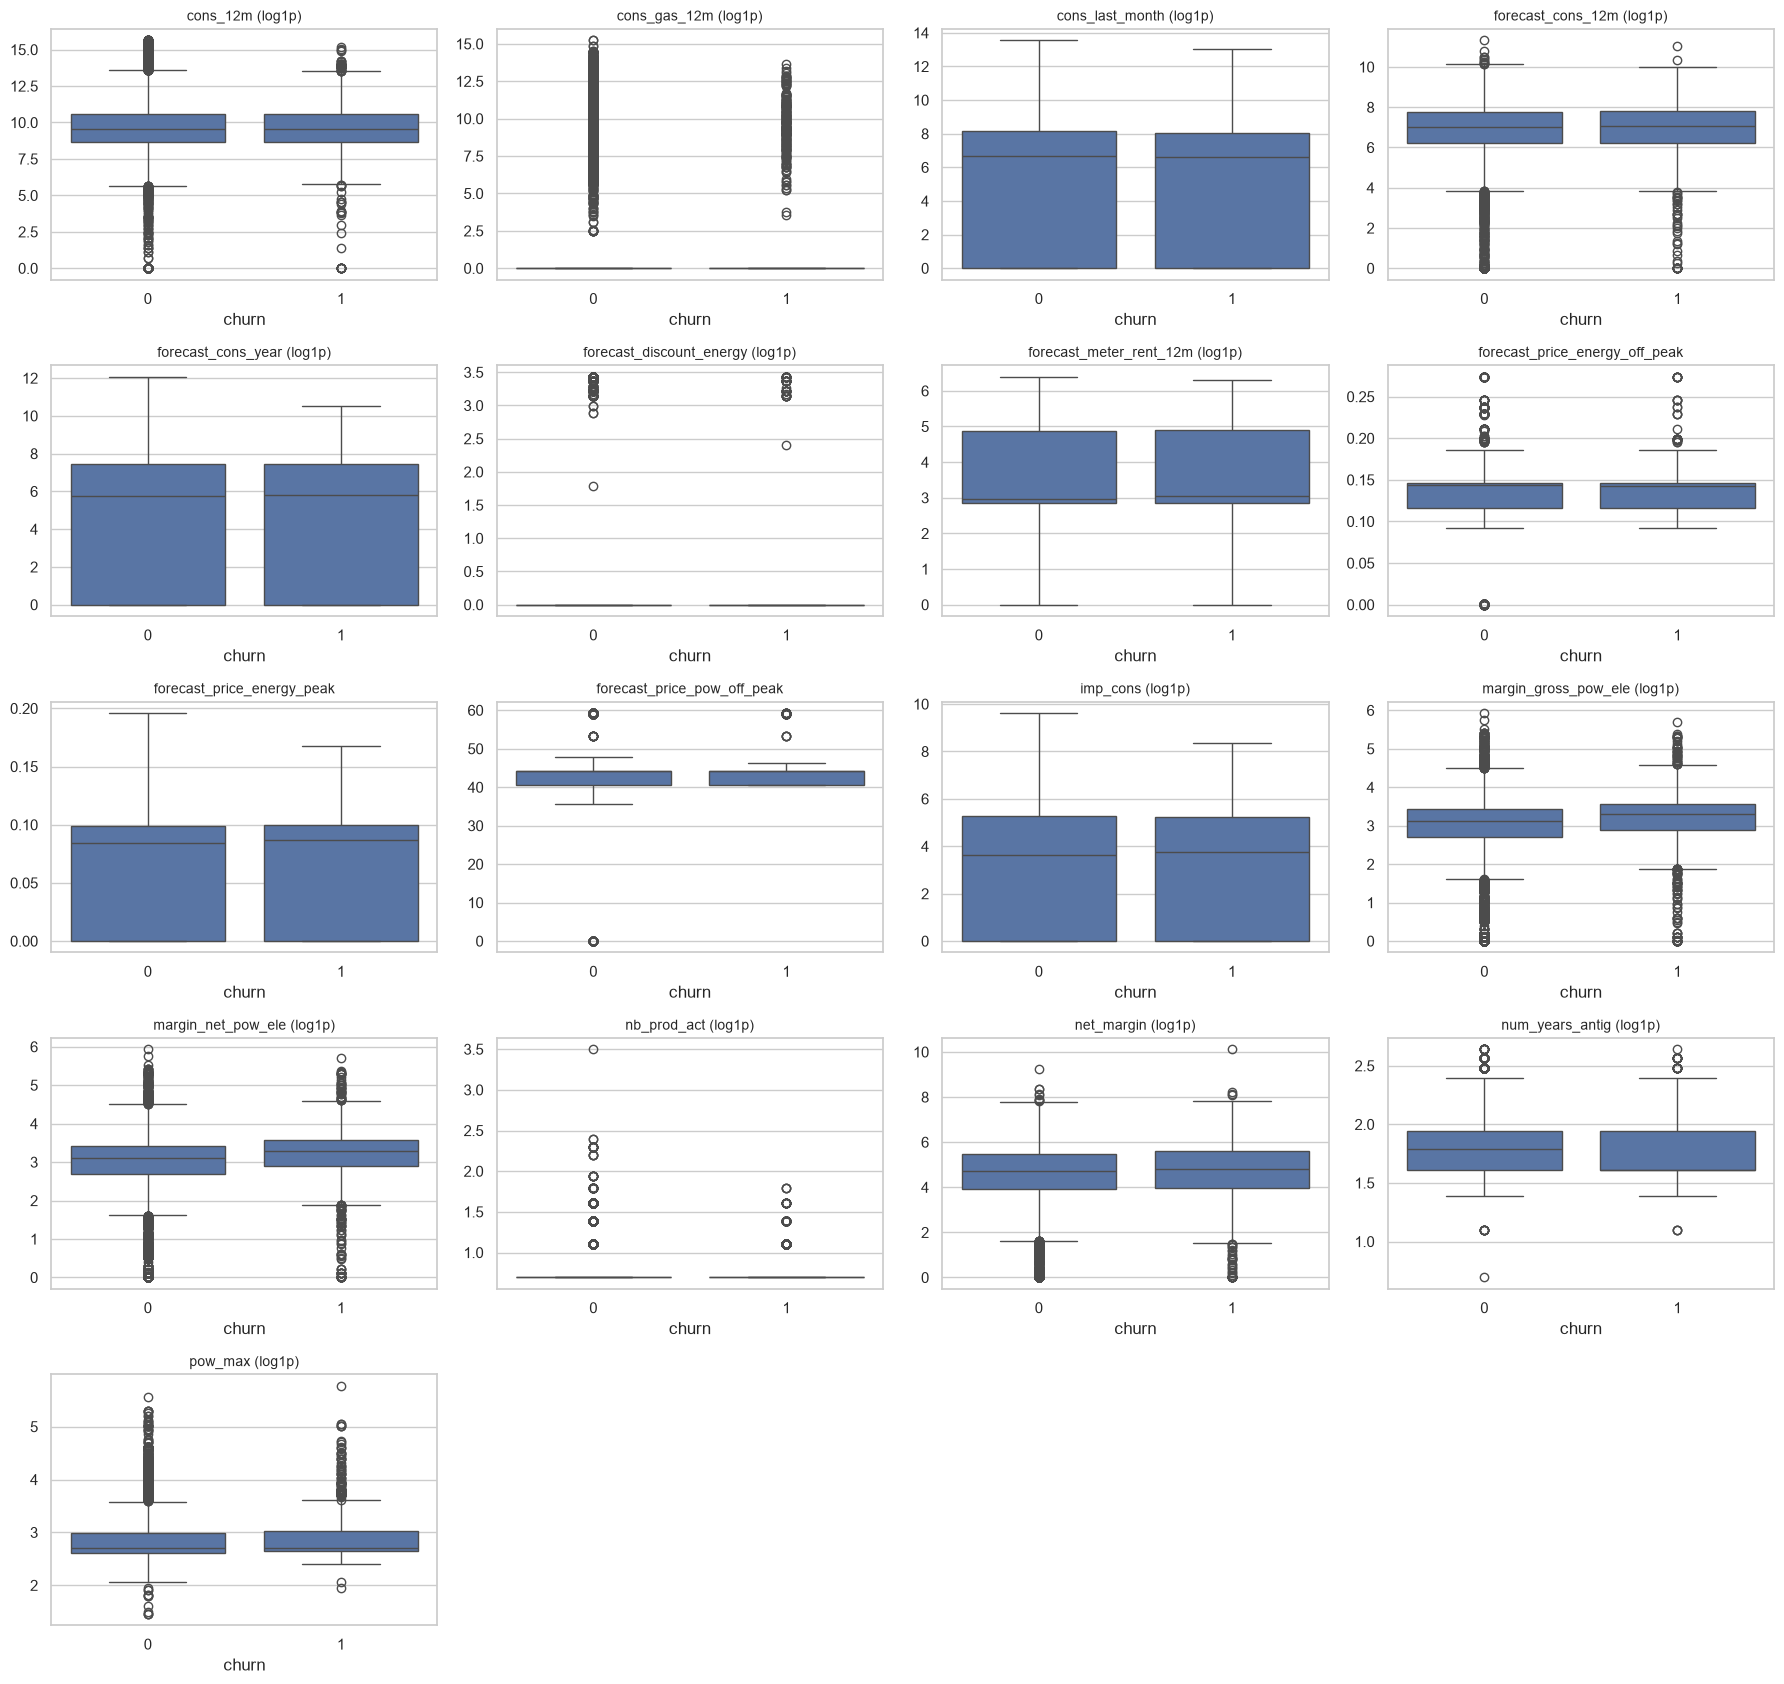

In [82]:
ncols = 4
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.4 * nrows))

for ax, c in zip(axes.ravel(), num_cols):
    y = np.log1p(client[c].clip(lower=0)) if c in skewed else client[c]
    sns.boxplot(data=client.assign(_y=y), x="churn", y="_y", ax=ax)
    ax.set_title(c + (" (log1p)" if c in skewed else ""), fontsize=10)
    ax.set_ylabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [83]:
display(client.groupby("churn")[num_cols].median().T.rename(columns={0: "stayed", 1: "churned"}))

churn,stayed,churned
cons_12m,14075.000000,14529.000000
cons_gas_12m,0.000000,0.000000
cons_last_month,800.000000,740.000000
forecast_cons_12m,1108.550000,1152.350000
forecast_cons_year,312.000000,326.000000
forecast_discount_energy,0.000000,0.000000
forecast_meter_rent_12m,18.650000,19.970000
forecast_price_energy_off_peak,0.143227,0.142819
forecast_price_energy_peak,0.083909,0.086803
forecast_price_pow_off_peak,44.311378,44.311378



- looking at the median numbers for gross margins , tenure , net margins  between those who churned and stayed; a majority of the customers with higher power margins churned

- looking at tenure lengths- Newer clients tended to churn more compared to more seasomed ones


- For most variables the medians of churned and retained clients are nearly identical (e.g. `cons_12m` ≈ 14,075 vs 14,529), so no single variable cleanly separates the two groups.


- The differences that do appear: churners have higher power margins (`margin_gross_pow_ele` median ≈ 26.0 vs 21.5, and `net_margin` ≈ 122 vs 112) and shorter tenure (`num_years_antig` median 4 vs 5 years).

- Single-variable AUC backs this up: margins ≈ 0.60 and tenure ≈ 0.58 are the strongest, while consumption variables sit at ≈ 0.50 (no signal alone).

- Hypothesis: PowerCo may be losing clients who pay higher margins, which fits a pricing story, and newer clients are less locked in.


##  Phase 6: Price data

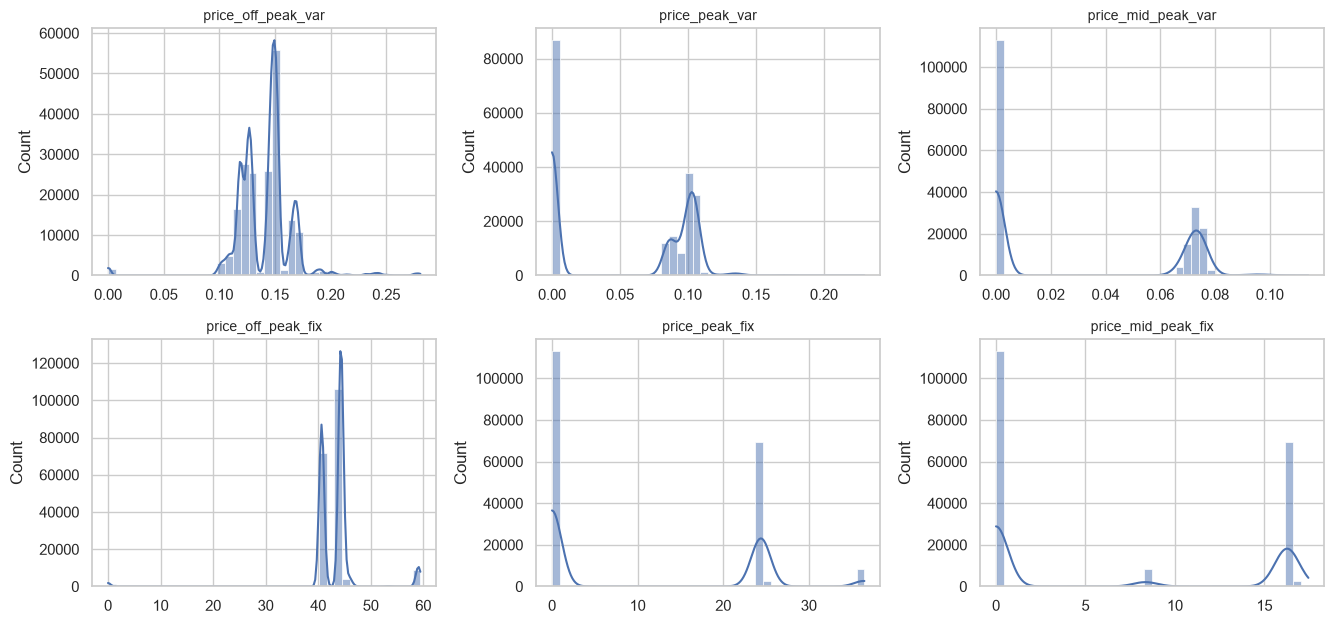

Share of zeros per price column:
price_off_peak_var    0.002
price_peak_var        0.450
price_mid_peak_var    0.585
price_off_peak_fix    0.008
price_peak_fix        0.585
price_mid_peak_fix    0.585
dtype: float64


In [84]:
price_cols = [c for c in price.columns if c.startswith("price_") and c != "price_date"]

dist_grid(price, price_cols, "hist", ncols=3)

# Zeros in peak/mid-peak columns: structural (no such tariff band) or missing?
print("Share of zeros per price column:")
print((price[price_cols] == 0).mean().round(3))

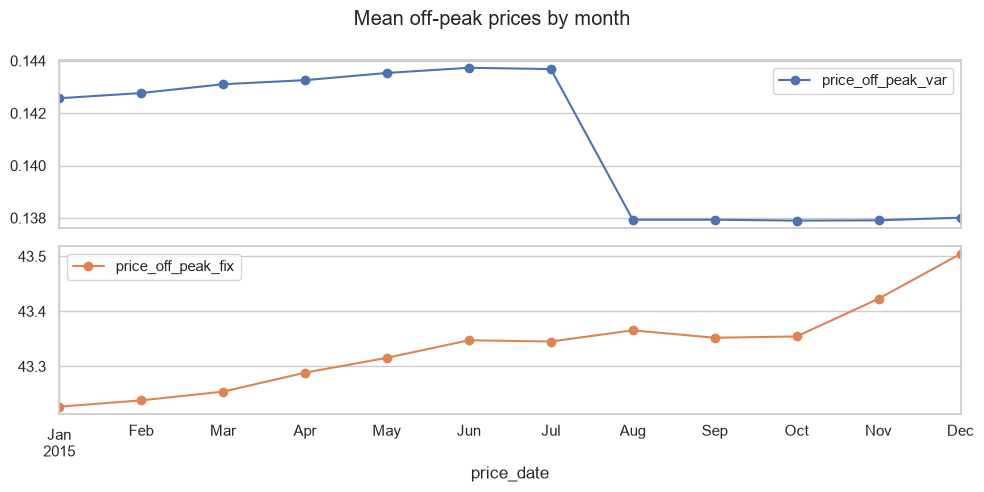

In [85]:
price.groupby("price_date")[["price_off_peak_var", "price_off_peak_fix"]].mean().plot(
    subplots=True, figsize=(10, 5), marker="o", title="Mean off-peak prices by month")
plt.tight_layout(); plt.show()

Clients with no price rows: 0


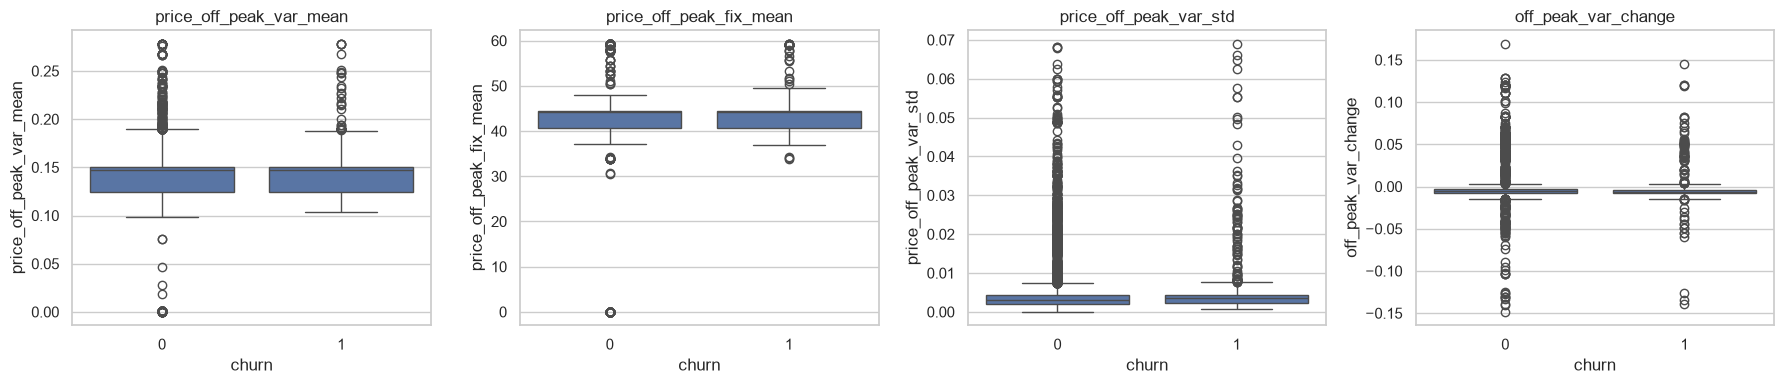

In [86]:
# Collapse to one row per client so it can join to churn
price_agg = price.groupby("id")[price_cols].agg(["mean", "std"])
price_agg.columns = ["_".join(c) for c in price_agg.columns]
price_agg = price_agg.reset_index()

# Price change: last month minus first month (off-peak variable)
piv = price.pivot_table(index="id", columns="price_date", values="price_off_peak_var")
chg = (piv.iloc[:, -1] - piv.iloc[:, 0]).rename("off_peak_var_change").reset_index()
price_agg = price_agg.merge(chg, on="id", how="left")

df = client.merge(price_agg, on="id", how="left")
print("Clients with no price rows:", df["price_off_peak_var_mean"].isna().sum())

pcols = ["price_off_peak_var_mean", "price_off_peak_fix_mean",
         "price_off_peak_var_std", "off_peak_var_change"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, pcols):
    sns.boxplot(data=df, x="churn", y=c, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()



- Peak and mid-peak prices are 0 in 45% to 58.5% of rows. The identical 58.5% across `price_mid_peak_var`, `price_peak_fix` and `price_mid_peak_fix` suggests the same clients simply have no peak/mid-peak band, so this is structural, not missing data.

- Market-wide, the average off-peak variable price is ~0.143 from Jan to Jul and drops to ~0.138 from Aug to Dec. The fixed price rises only slightly (43.2 to 43.5). There was no broad price hike in 2015; if anything, a mid-year cut.

- Price features are weak predictors on their own (AUC 0.47-0.55). The best is price volatility (`price_off_peak_var_std`, ≈ 0.55), and mean off-peak price points slightly the opposite way to "higher price causes churn".

- Conclusion: the price hypothesis is not strongly supported by these annual aggregates, which doesn't rule it out.


## Phase 7: Correlation Analysis

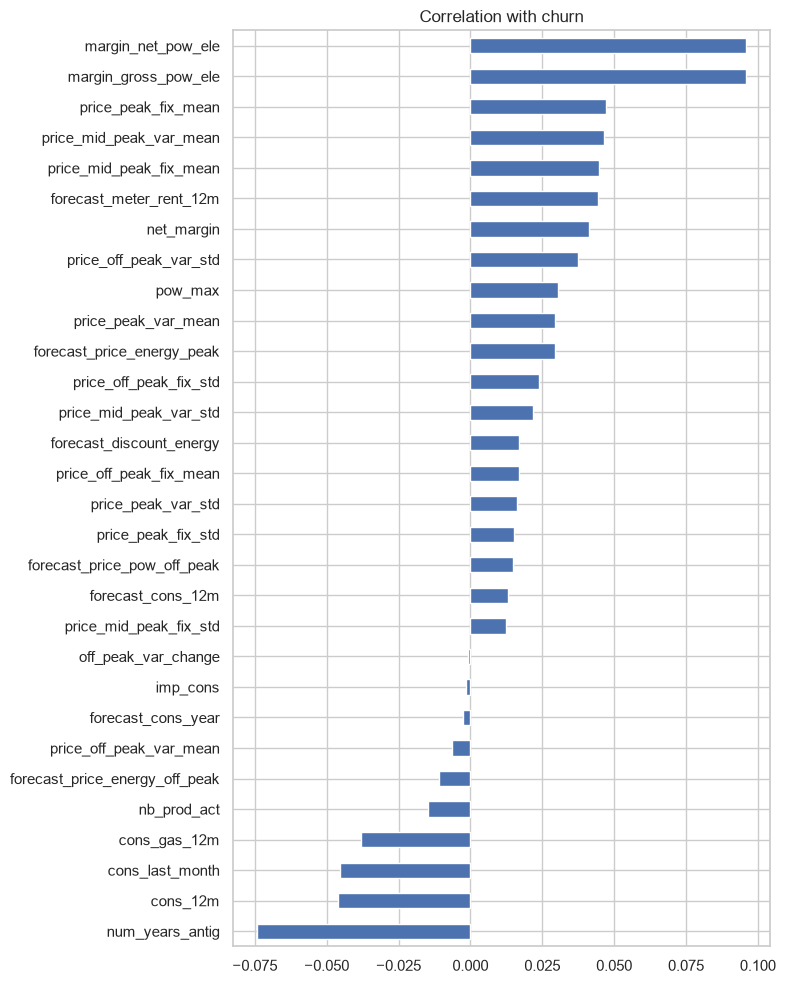

margin_net_pow_ele       margin_gross_pow_ele              0.999914
price_peak_var_mean      forecast_price_energy_peak        0.994046
price_mid_peak_fix_mean  price_mid_peak_var_mean           0.991544
price_peak_fix_mean      price_mid_peak_var_mean           0.987691
price_mid_peak_fix_std   price_peak_fix_std                0.983871
price_mid_peak_fix_mean  price_peak_fix_mean               0.974096
imp_cons                 forecast_cons_year                0.969395
cons_last_month          cons_12m                          0.968212
price_mid_peak_fix_std   price_mid_peak_var_std            0.952631
price_off_peak_var_mean  forecast_price_energy_off_peak    0.951222
price_peak_fix_std       price_mid_peak_var_std            0.950627
price_off_peak_fix_mean  forecast_price_pow_off_peak       0.934633
price_peak_fix_mean      forecast_meter_rent_12m           0.885983
price_mid_peak_var_mean  forecast_meter_rent_12m           0.869756
price_mid_peak_fix_mean  forecast_meter_rent_12m

In [87]:
price_feats = [c for c in df.columns if c.startswith("price_") and c.endswith(("_mean", "_std"))]
corr_cols = num_cols + price_feats + ["off_peak_var_change", "churn"]
corr = df[corr_cols].corr()
corr["churn"].drop("churn").sort_values().plot.barh(figsize=(8, 10), title="Correlation with churn")
plt.tight_layout(); plt.show()

# Highly correlated pairs (multicollinearity candidates)
mask = np.triu(np.ones_like(corr, dtype=bool))
pairs = corr.where(~mask).stack()
print(pairs[pairs.abs() > 0.8].sort_values(ascending=False))

- the columns with most correlation(absolute) to churn are carry more signal but among'st them are highly correelated pairs and thus the need to pick one from the pair based of their individual auc's and correlation to the churn label

- correlations with churn are all small (the strongest is about 0.10, for the margins), which is normal for a binary target but supports modest signal